# Re-identification of sea turtles from body parts

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/sadda/turtle_re_id/blob/master/examples/introduction.ipynb)

This notebook shows how to use the `animal_re_id` package to identify sea turtles in new photos (the **query**) by comparing them with photos of already known turtles (the **database**). Instead of comparing whole images, the turtles are first segmented into body parts (head, front flippers, hind flippers), and each body part is matched separately. The results of all body parts are then merged into one ranked list of candidate identities per query. The identification operates on an encounter (observation) level, where the identity is assigned to each encounter and not to individual images.

The workflow consists of:

1. **Detection** – the TurtleDetector finds the body parts in every photo.
2. **Re-identification** – every body part of the query is compared with the same body part in the database.
3. **Verification** – the most promising candidate pairs are exported for manual verification in a visual app.
4. **Propagation** – the verified answers are used to assign identities to the query.

### What is computed and when

All computed results are stored and reused. The first run is slow, because all photos in the database have to be processed. Once the database is built, running the notebook again or adding new photos is fast, because only what is new is computed. This makes the workflow usable on a regular computer without a GPU.

| Part | When is it downloaded/computed |
|------|--------------------------------|
| Installing the packages | once |
| Downloading the models | once |
| Downloading the example data | once |
| Processing database photos | once |
| Processing query photos | only for new photos |

Google Colab deletes all files when the session ends, so every new session is a slow first run.

## 0. Configuration and Data Preparation

When running in Google Colab, we first install the `animal_re_id` package. Then we load all required functions.

In [1]:
import sys

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    %pip install -q "animal-re-id[models] @ git+https://github.com/sadda/turtle_re_id"

In [2]:
import os
import urllib.request
import warnings
import zipfile

import matplotlib.pyplot as plt
import pandas as pd
from wildlife_datasets.datasets import Dataset_FolderStructured

from animal_re_id.datasets import TurtlesFromMetadata
from animal_re_id.datasets.utils import check_image_ids
from animal_re_id.models import EncounterPredictions, Wildfusion_Similarity, get_pipeline_aliked, get_pipeline_miew, merge_data, run_detection_cached, turtle_detector
from animal_re_id.verification import answers_to_predictions, generate_answers

warnings.filterwarnings("ignore", message=".*copying from a non-meta parameter.*")

The notebook expects the query set in the folder `root_query` and the database in the folder `root_database`. We specify that we run the computation on CPU, not GPU. The option `img_load="bbox"` means that every body part is cropped by its bounding box before matching, and `matching_parts` lists the body parts that are used for re-identification.

In [3]:
root_query = "data_identification/query"
root_database = "data_identification/database"
root_cache = "output/cache_Example_identification"

device = "cpu"
img_load = "bbox"
matching_parts = ["heads", "front flippers", "hind flippers"]

We now download a small subset of [SeaTurtleID2022](https://www.kaggle.com/datasets/wildlifedatasets/seaturtleid2022):
- `database`: 4 turtles with 2-5 photos each, stored as `<identity>/<photo>`.
- `query`: 6 encounters with 2 photos each, stored as `<date>/<encounter>/<photo>`. Two of these turtles (`t048` and `t323`) are not in the database. The true identities are given at the end of the notebook so that the results can be checked.

In [4]:
url = "https://raw.githubusercontent.com/sadda/wildlife-labels/refs/heads/main/Example/data_identification.zip"
root_data = "data_identification"
file_name = "data.zip"

if not os.path.exists(root_query):
    urllib.request.urlretrieve(url, file_name)
    with zipfile.ZipFile(file_name) as f:
        f.extractall(root_data)
    os.remove(file_name)

    for root in [root_query, root_database]:
        os.remove(f"{root}/metadata.csv")
        os.remove(f"{root}/segmentation.csv")

### Using your own data

Using your own data is simple, provided they have a uniform structure. The photos only need to be organized into folders, which are turned into metadata by the WildlifeDatasets library. Its [documentation](https://wildlifedatasets.github.io/wildlife-datasets/adding/) shows multiple ways how to convert your own data into the structure required to run this notebook. In this notebook, the folder levels are described by `levels` in `Dataset_FolderStructured` (see the next section). If the identities or encounters are stored in a table instead of folders, the table can be saved as `metadata.csv` with the columns `image_id`, `identity`, `path` and `encounter_id`.

## 1. Detection

The metadata are created from the folder structure by `Dataset_FolderStructured`, where `levels` names the folder levels below the root:

- In the database, the folder is the identity and there is no information about encounters.
- In the query, the identity is unknown, and the photos of the same turtle taken on the same day form one **encounter** (`<date>/<folder>`). Predictions are made for whole encounters, so the evidence from all photos of an encounter is combined.

The [TurtleDetector](https://huggingface.co/BVRA/TurtleDetector) then detects the turtle body, the head and the four flippers in every photo and stores their bounding boxes, masks, labels and confidence scores. Both tables are saved next to the photos as `metadata.csv` and `segmentation.csv`. Finally, example photos from both the query and the database are plotted.

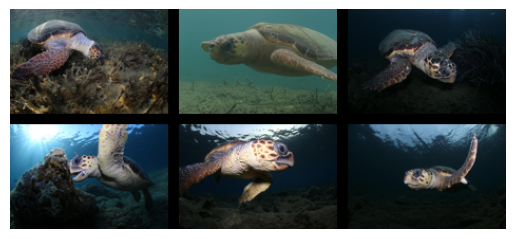

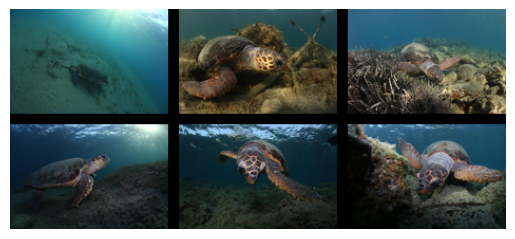

In [5]:
model = turtle_detector()
data = [
    (root_query, False, ("date", "encounter")),
    (root_database, True, ("identity",)),
]
for root, is_database, levels in data:
    dataset = Dataset_FolderStructured(root, levels=levels)
    metadata = dataset.metadata.copy()
    metadata["encounter_id"] = metadata["image_id"] if is_database else metadata["date"] + "/" + metadata["encounter"]
    metadata.to_csv(f"{root}/metadata.csv", index=False)

    run_detection_cached(dataset, model, f"{root}/segmentation.csv")

    dataset.plot_grid(idx=range(6), n_rows=2, n_cols=3, rotate=False)

The dataset in `TurtlesFromMetadata` loads `metadata.csv` together with `segmentation.csv`. Every detected body part becomes one row, and detections with low confidence are removed. The table shows how many body parts of each type were kept in the query and in the database.

In [6]:
dataset_kwargs = {"img_load": img_load}
query_dataset = TurtlesFromMetadata(root_query, dataset_kwargs=dataset_kwargs)
database_dataset = TurtlesFromMetadata(root_database, dataset_kwargs=dataset_kwargs)
pd.DataFrame(
    {
        "query": query_dataset.wildlife_dataset.metadata["label"].value_counts(),
        "database": database_dataset.wildlife_dataset.metadata["label"].value_counts(),
    }
)

,query,database
label,,
flipper_fl,11,14
flipper_fr,10,12
flipper_hl,2,3
flipper_hr,7,2
head,12,16
turtle,12,17


The detector labels are grouped into **matching parts**: `heads`, `front flippers` (left and right) and `hind flippers` (left and right). Each grid shows the query crops of one matching part.

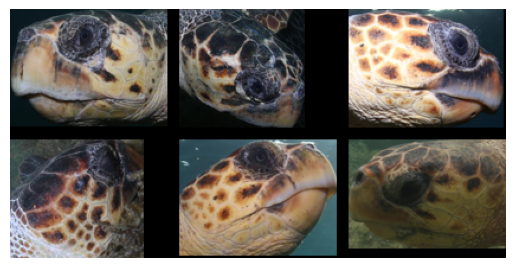

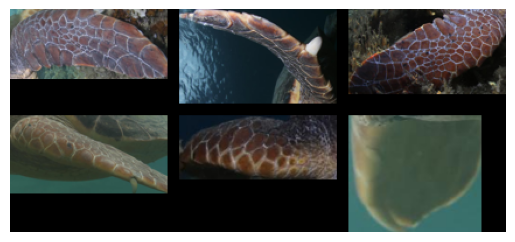

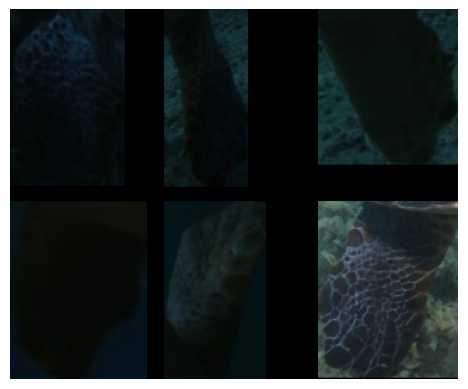

In [7]:
for matching_part in matching_parts:
    wildlife_dataset = query_dataset.for_matching_part(matching_part).wildlife_dataset
    wildlife_dataset.plot_grid(n_rows=2, n_cols=3, rotate=True)

## 2. Re-identification based on individual parts

Every matching part is matched separately, always comparing the query crops with the database crops of the same part:

- **Similarity:** `Wildfusion_Similarity` first uses the MiewID global descriptor to select the `B` most similar database crops for every query crop. These candidates are then compared by local keypoints (ALIKED keypoints matched by LightGlue), and the similarity is the number of matched keypoints.
- **Caching:** extracted features and keypoint matches are cached in `root_cache`, so running the cell again is fast.

`EncounterPredictions.classify` turns the similarity matrix into predictions: for every query encounter, it takes the best similarity over its photos and ranks the database identities (at most `k_max` of them). Finally, `merge_data` merges the matching parts: for every encounter and candidate identity, it keeps the evidence of the body part with the highest similarity.

In [8]:
cache_prefix = f"{root_cache}/{img_load}"
miew = get_pipeline_miew(device=device, cache_prefix=cache_prefix)
aliked = get_pipeline_aliked(device=device, cache_prefix=cache_prefix)
B = 5

predictions = []
for matching_part in matching_parts:
    query = query_dataset.for_matching_part(matching_part).wildlife_dataset
    database = database_dataset.for_matching_part(matching_part).wildlife_dataset
    check_image_ids(query.metadata, database.metadata)

    similarity = Wildfusion_Similarity(miew, aliked, B=B)(query, database)
    prediction = EncounterPredictions.classify(similarity, query, database, matching_part, "miew-aliked", k_max=10)
    predictions.append(prediction)

merged = merge_data(predictions)

`get_top_predictions` returns the best prediction for every query encounter:

- `prediction`: the database identity ranked first.
- `matching_part`: the body part that produced the prediction.
- `similarity_score`: the number of matched keypoints.


All four turtles that are in the database are identified correctly, with scores from 49 to 94 matched keypoints (see the images below). The two new individuals (`t048` and `t323`) cannot be identified correctly, because their identity is not among the candidates. Their best predictions (`t217` and `t023`) have much lower scores, 15 and 17.

In this example, a threshold on the score would therefore separate the known turtles from the new ones. In general, this is not reliable:

- Scores of different body parts are not directly comparable. Head and flipper crops differ in size and texture, so they produce different numbers of keypoints.
- With more data, wrong matches with high scores and correct matches with low scores do occur.

For these reasons, the predictions are not accepted automatically but checked by a human in the next step.

In [9]:
top_predictions = merged.get_top_predictions()
top_predictions

,encounter,prediction,matching_part,similarity_score
0,2016-09-11/1,t217,heads,15.0
1,2018-06-22/1,t217,heads,58.0
2,2019-09-01/1,t023,hind flippers,17.0
3,2019-09-02/1,t023,front flippers,94.0
4,2021-06-22/1,t243,front flippers,67.0
5,2021-06-27/1,t441,heads,49.0


## 3. Verification

We convert the merged predictions into candidate pairs for verification. Every row is one pair of a query encounter and a candidate database identity, including the two images that produced the match, the matching part and the raw number of matched keypoints (`similarity_orig`). `max_per_encounter` limits the number of candidates per query encounter, and `max_matches` limits the total number of pairs.

The pairs are saved to `verification_data.csv`, which is the input format of the [Image Comparator app](https://github.com/sadda/image-comparator). There, an annotator decides for every pair whether the two turtles are the same, and the answers are saved to `answers.csv`. Manual verification is optional for this notebook.

In [10]:
file_name_verification = "output/verification_data.csv"

verification = merged.extract_highest_predictions(max_matches=40, max_per_encounter=4, sort_by="similarity_orig")
verification = verification.sort_values(["encounter1", "similarity_orig"], ascending=[True, False], ignore_index=True)
verification.to_csv(file_name_verification, index=False)
verification[["encounter1", "identity1", "identity2", "matching_part", "similarity_orig"]]

,encounter1,identity1,identity2,matching_part,similarity_orig
0,2016-09-11/1,unknown,t217,heads,15.0
1,2016-09-11/1,unknown,t243,heads,13.0
2,2016-09-11/1,unknown,t441,heads,11.0
3,2016-09-11/1,unknown,t023,front flippers,3.0
4,2018-06-22/1,unknown,t217,heads,58.0
5,2018-06-22/1,unknown,t023,hind flippers,16.0
6,2018-06-22/1,unknown,t243,front flippers,10.0
7,2018-06-22/1,unknown,t441,front flippers,3.0
8,2019-09-01/1,unknown,t023,hind flippers,17.0
9,2019-09-01/1,unknown,t243,heads,14.0


## 4. Propagation

If the verification has been performed manually, copy the file `answers.csv` to the `output` folder and load it via

```python
answers = pd.read_csv("output/answers.csv")
```

To run this example without the app, `generate_answers` simulates an annotator who knows the true identities and selects either `same` or `different`.

`answers_to_predictions` converts the answers into one prediction for every query encounter:

- **database identity** (for example `t023`): one candidate was answered `same`, so the encounter belongs to this turtle.
- `new`: all candidates were answered `different`, so the turtle is most likely not in the database.
- `conflict`: two different turtles were answered `same`. The answers contradict each other and need to be checked again.
- `None`: no candidate was answered `same`, but some were not answered.

All four known turtles were assigned their correct identity, and both turtles that are not in the database (`t048` and `t323`) were recognised as `new`. Unlike the threshold on the similarity score in section 2, this decision is made by the annotator, and it is reliable even when the scores of correct and wrong matches overlap.

In [11]:
true_identities = {
    "2016-09-11/1": "t048",
    "2018-06-22/1": "t217",
    "2019-09-01/1": "t323",
    "2019-09-02/1": "t023",
    "2021-06-22/1": "t243",
    "2021-06-27/1": "t441",
}

answers = generate_answers(verification, true_identities)
predictions_verified = answers_to_predictions(answers)
predictions_verified

,encounter,prediction
0,2016-09-11/1,new
1,2018-06-22/1,t217
2,2019-09-01/1,new
3,2019-09-02/1,t023
4,2021-06-22/1,t243
5,2021-06-27/1,t441


## 5. Visualisation of matches

`visualise_match` shows why a pair was proposed. For the best candidate of every query encounter, it matches the two crops again with ALIKED and LightGlue and connects the matched keypoints by lines. `init_threshold=0.5` keeps only confident matches, so the number of lines roughly corresponds to the score in `similarity_orig`. The title gives the body part, the candidate identity and the number of matched keypoints.

For a correct match, many lines connect corresponding scales and spots of the two crops and run roughly in parallel. For the two new individuals, the best candidate is a wrong turtle: there are fewer lines, and they cross each other because they connect parts that do not correspond. These are the same images that the annotator compares in the Image Comparator app.

Loaded LightGlue model


100%|█████████████████████████████████████████████████████████████████| 1/1 [00:00<00:00,  3.95it/s]


Loaded LightGlue model


100%|█████████████████████████████████████████████████████████████████| 1/1 [00:00<00:00, 38.92it/s]


Loaded LightGlue model


...

100%|█████████████████████████████████████████████████████████████████| 1/1 [00:00<00:00, 38.81it/s]


Loaded LightGlue model


100%|█████████████████████████████████████████████████████████████████| 1/1 [00:00<00:00, 38.82it/s]


Loaded LightGlue model


100%|█████████████████████████████████████████████████████████████████| 1/1 [00:00<00:00, 38.73it/s]


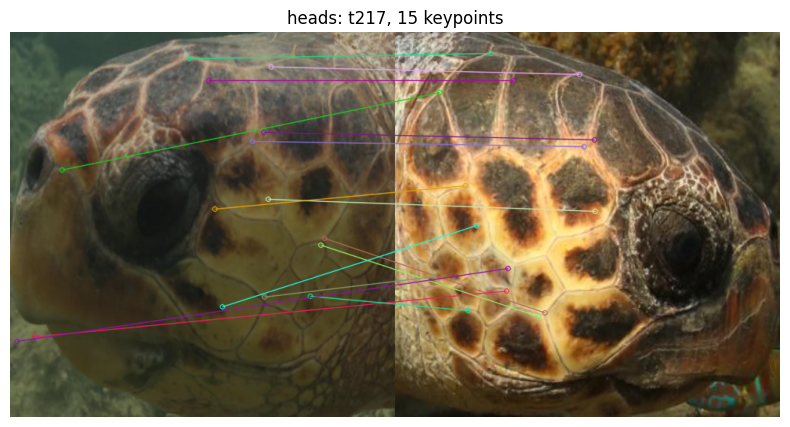

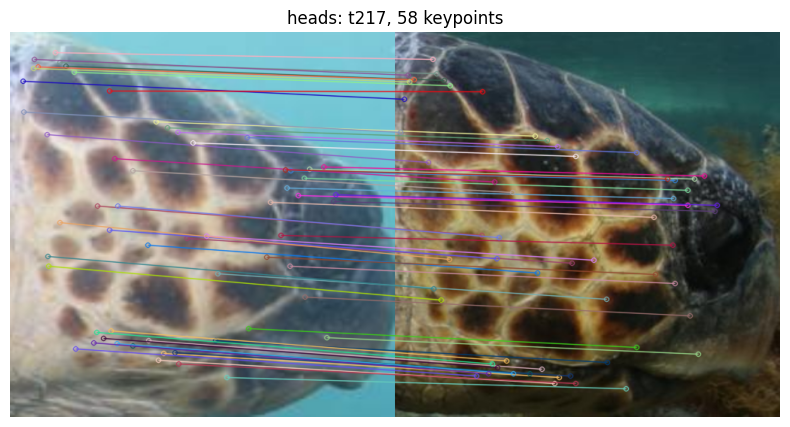

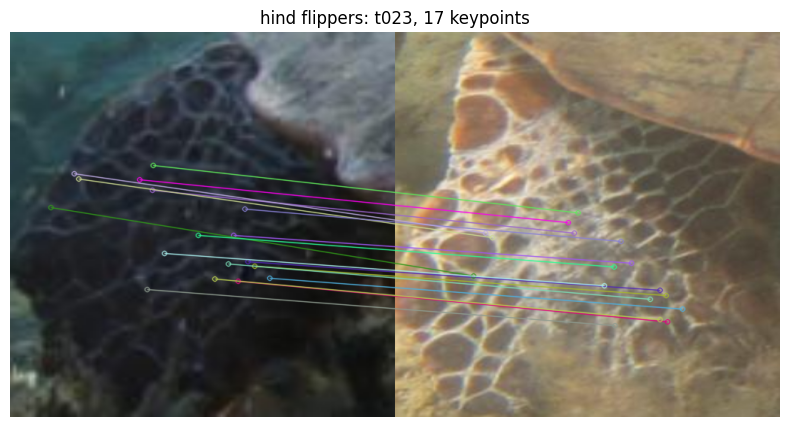

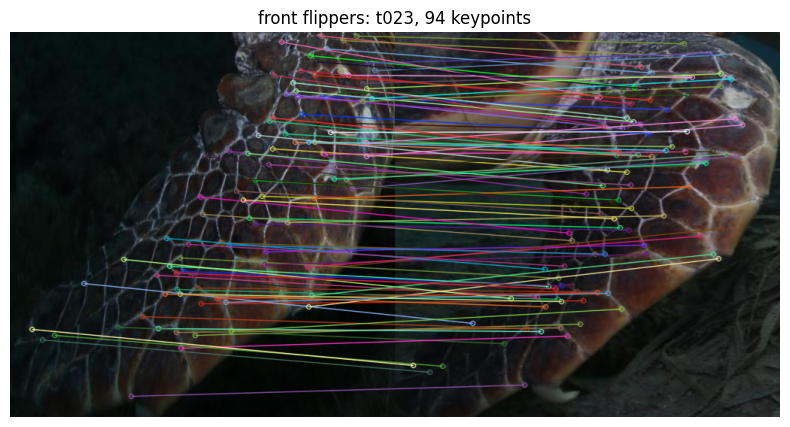

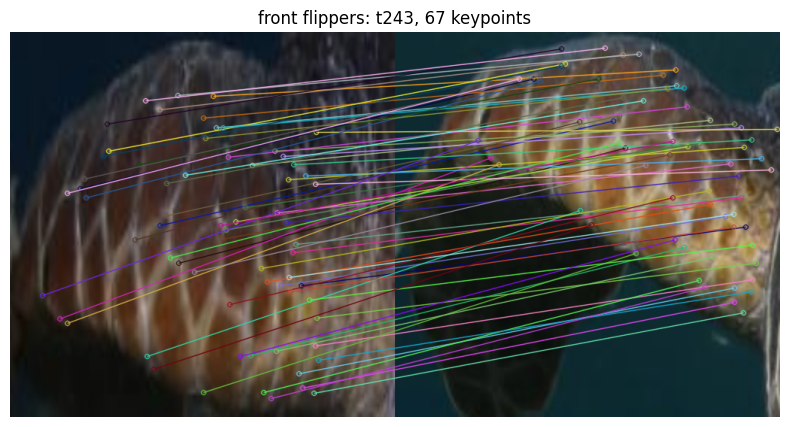

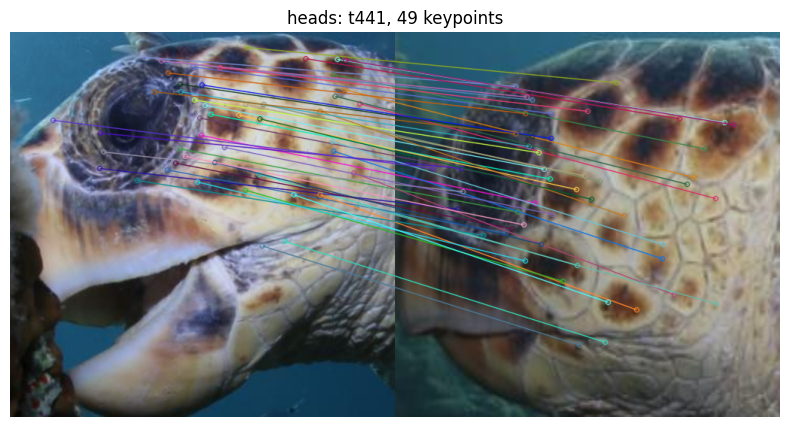

In [12]:
from animal_re_id.models import visualise_match

for _, verification_encounter in verification.groupby("encounter1"):
    row = verification_encounter.iloc[0]
    query = query_dataset.for_matching_part(row["matching_part"]).wildlife_dataset
    database = database_dataset.for_matching_part(row["matching_part"]).wildlife_dataset
    fig, ax = plt.subplots(figsize=(10, 5))
    visualise_match(query, database, row, aliked, "aliked", init_threshold=0.5, ax=ax)
    ax.set_title(f"{row['matching_part']}: {row['identity2']}, {row['similarity_orig']:.0f} keypoints")